# 23CSE301 — Machine Learning Capstone — Review 1
## Regression Track — Battery State-of-Health

**Target:** predict **State-of-Health (SOH, %)**
of a battery cell — not raw Capacity directly. Source: NASA Battery Dataset
(Kaggle, `patrickfleith/nasa-battery-dataset`, `cleaned_dataset`) —
`metadata.csv` plus the ~7,000 per-cycle raw CSVs it references via its
`filename` column.

> **Reproducibility:** `random_state=42` throughout (§7.1).


## 0. Imports & configuration

In [38]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    GridSearchCV,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler, PolynomialFeatures

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.autolayout"] = True

# Dataset location.
# Defaults to the repo-relative folder that data/README.md tells you to
# populate. To point this at a different folder on your own machine, set the
# CHARGEIQ_REGRESSION_DATA environment variable instead of editing this cell.
DATASET_DIR = os.environ.get(
    "CHARGEIQ_REGRESSION_DATA",
    os.path.join("..", "data", "Regression_Dataset")
)

DATA_PATH = os.path.join(DATASET_DIR, "metadata.csv")
RAW_DIR = os.path.join(DATASET_DIR, "data")

NOMINAL_CAPACITY = 2.0

print("Dataset folder:", DATASET_DIR)
print("Metadata path:", DATA_PATH)
print("Raw data folder:", RAW_DIR)

if os.path.exists(DATA_PATH):
    print("metadata.csv found!")

if os.path.exists(RAW_DIR):
    print("data folder found!")

Dataset folder: ../data/Regression_Dataset
Metadata path: ../data/Regression_Dataset/metadata.csv
Raw data folder: ../data/Regression_Dataset/data
metadata.csv found!
data folder found!


## 1. Load & audit the raw file (Section A1)

In [39]:
df_raw = pd.read_csv(DATA_PATH)
for col in ["Capacity", "Re", "Rct"]:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

print("Shape:", df_raw.shape)
print("\nRow type counts:\n", df_raw["type"].value_counts())
print("\nUnique batteries:", df_raw["battery_id"].nunique())
print("\nMissing values per column:\n", df_raw.isna().sum())

Shape: (7565, 10)

Row type counts:
 type
charge       2815
discharge    2794
impedance    1956
Name: count, dtype: int64

Unique batteries: 34

Missing values per column:
 type                      0
start_time                0
ambient_temperature       0
battery_id                0
test_id                   0
uid                       0
filename                  0
Capacity               4796
Re                     5618
Rct                    5618
dtype: int64


**Observation (A1):** 

as before, missingness is structural :-
- `Capacity` only on `discharge` rows, `Re`/`Rct` only on `impedance` rows. 
- `charge` rows carry none of these but do have their own raw per-cycle curve.

### 1b. Structural join: one row per discharge cycle

In [40]:
def parse_start_time(s):
    nums = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", str(s))
    if len(nums) < 6:
        return pd.NaT
    y, mo, d, h, mi, se = (float(n) for n in nums[:6])
    try:
        return pd.Timestamp(int(y), int(mo), int(d), int(h), int(mi), int(round(se)))
    except (ValueError, OverflowError):
        return pd.NaT

df_raw["parsed_time"] = df_raw["start_time"].apply(parse_start_time)

discharge = df_raw[df_raw["type"] == "discharge"].sort_values(["battery_id", "test_id"]).copy()
impedance = df_raw[df_raw["type"] == "impedance"].sort_values(["battery_id", "test_id"]).copy()
charge = df_raw[df_raw["type"] == "charge"].sort_values(["battery_id", "test_id"]).copy()

discharge["cycle_index"] = discharge.groupby("battery_id").cumcount() + 1

disc_slim = discharge[["battery_id", "test_id", "ambient_temperature", "cycle_index", "Capacity", "filename"]]
imp_slim = impedance[["battery_id", "test_id", "Re", "Rct"]]

analysis_df = pd.merge_asof(
    disc_slim.sort_values("test_id"), imp_slim.sort_values("test_id"),
    on="test_id", by="battery_id", direction="backward",
)
print("Per-discharge-cycle table:", analysis_df.shape)
analysis_df.head()


Per-discharge-cycle table: (2794, 8)


,battery_id,test_id,ambient_temperature,cycle_index,Capacity,filename,Re,Rct
0,B0034,0,24,1,0.745930,01805.csv,NaN,NaN
1,B0046,0,4,1,1.728239,00553.csv,NaN,NaN
2,B0041,0,4,1,0.055620,02996.csv,NaN,NaN
3,B0056,0,4,1,0.785278,07062.csv,NaN,NaN
4,B0040,0,24,1,0.673463,01231.csv,NaN,NaN


## 2. Feature extraction from the raw per-cycle CSVs


Each `discharge`/`charge` row's `filename` points to a raw curve with columns
`Voltage_measured, Current_measured, Temperature_measured, Current_load/charge,
Voltage_load/charge, Time`.

**Why not just use the full curve?** 

Checking one discharge file end to end: the
load current holds at ≈-0.995 A until cutoff at 2.47 V, `Time≈6179s` — working
out `0.995A × (6179s/3600) ≈ 1.71 Ah` lines up almost exactly with that row's
`Capacity = 1.674 Ah`. That's expected, since Capacity **is defined as** the
discharge current integrated over time — but it means a feature built from the
**full** discharge curve (total duration, full-curve integral) is just the
target restated, not a real predictor. We deliberately avoid that:

- **From each discharge cycle's own curve** — only the **first ~300 seconds**:
  voltage-sag rate and temperature-rise rate under load. This reflects internal
  resistance, not how long the discharge ran.
- **From the *preceding* charge cycle** (nearest-prior per battery, same join
  pattern as `Re`/`Rct`): full charge duration, max temperature, and time to
  reach the CC→CV voltage threshold. This is a separate physical process, so
  using its full curve doesn't restate this discharge's capacity.

In [41]:
def extract_discharge_early_features(path, early_seconds=300):
    d = pd.read_csv(path, usecols=["Voltage_measured", "Temperature_measured", "Time"])
    v0, t0 = d["Voltage_measured"].iloc[0], d["Temperature_measured"].iloc[0]
    window = min(early_seconds, 0.2 * d["Time"].max())
    early = d[d["Time"] <= window]
    if len(early) < 2:
        early = d.iloc[:max(2, int(0.1 * len(d)))]
    v_end, t_end, temp_end = early["Voltage_measured"].iloc[-1], early["Time"].iloc[-1], early["Temperature_measured"].iloc[-1]
    return {
        "early_voltage_sag_rate": (v0 - v_end) / t_end if t_end > 0 else np.nan,
        "early_temp_rise_rate": (temp_end - t0) / t_end if t_end > 0 else np.nan,
    }

def extract_charge_features(path, cv_threshold=4.15):
    d = pd.read_csv(path, usecols=["Voltage_measured", "Temperature_measured", "Time"])
    duration, max_temp = d["Time"].max(), d["Temperature_measured"].max()
    above = d[d["Voltage_measured"] >= cv_threshold]
    time_to_cv = above["Time"].iloc[0] if len(above) else duration
    return {"charge_duration": duration, "charge_max_temp": max_temp, "charge_time_to_cv": time_to_cv}


In [42]:
disc_feats = []
for _, row in discharge.iterrows():
    try:
        feats = extract_discharge_early_features(f"{RAW_DIR}/{row['filename']}")
    except (FileNotFoundError, pd.errors.EmptyDataError, KeyError):
        feats = {"early_voltage_sag_rate": np.nan, "early_temp_rise_rate": np.nan}
    feats["filename"] = row["filename"]
    disc_feats.append(feats)
disc_feats_df = pd.DataFrame(disc_feats)

chg_feats = []
for _, row in charge.iterrows():
    try:
        feats = extract_charge_features(f"{RAW_DIR}/{row['filename']}")
    except (FileNotFoundError, pd.errors.EmptyDataError, KeyError):
        feats = {"charge_duration": np.nan, "charge_max_temp": np.nan, "charge_time_to_cv": np.nan}
    feats["battery_id"], feats["test_id"] = row["battery_id"], row["test_id"]
    chg_feats.append(feats)
chg_feats_df = pd.DataFrame(chg_feats).sort_values("test_id")

print("Discharge-curve features:", disc_feats_df.shape, " | missing:\n", disc_feats_df.isna().sum().to_dict())
print("Charge-curve features:", chg_feats_df.shape, " | missing:\n", chg_feats_df.isna().sum().to_dict())

# Merge own discharge-curve features (direct join, same file) ...
analysis_df = analysis_df.merge(disc_feats_df, on="filename", how="left")
# ... and the nearest-preceding charge cycle's features (asof join, like Re/Rct)
analysis_df = pd.merge_asof(
    analysis_df.sort_values("test_id"), chg_feats_df,
    on="test_id", by="battery_id", direction="backward",
)
print("\nEnriched analysis table:", analysis_df.shape)
analysis_df.head()


Discharge-curve features: (2794, 3)  | missing:
 {'early_voltage_sag_rate': 0, 'early_temp_rise_rate': 0, 'filename': 0}
Charge-curve features: (2815, 5)  | missing:
 {'charge_duration': 0, 'charge_max_temp': 0, 'charge_time_to_cv': 0, 'battery_id': 0, 'test_id': 0}

Enriched analysis table: (2794, 13)


,battery_id,test_id,ambient_temperature,cycle_index,Capacity,filename,Re,Rct,early_voltage_sag_rate,early_temp_rise_rate,charge_duration,charge_max_temp,charge_time_to_cv
0,B0034,0,24,1,0.745930,01805.csv,NaN,NaN,0.003128,0.034919,NaN,NaN,NaN
1,B0053,0,4,1,1.069142,06672.csv,NaN,NaN,0.002306,0.009568,NaN,NaN,NaN
2,B0033,0,24,1,0.068426,02413.csv,NaN,NaN,0.000833,0.032648,NaN,NaN,NaN
3,B0054,0,4,1,0.739935,06809.csv,NaN,NaN,0.002849,0.014182,NaN,NaN,NaN
4,B0045,0,4,1,1.081979,00185.csv,NaN,NaN,0.001641,-0.000759,NaN,NaN,NaN


## 3. Exploratory Data Analysis (Section A2)

In [45]:
battery_summary = analysis_df.groupby("battery_id")["Capacity"].agg(
    n_cycles="size", missing_frac=lambda s: s.isna().mean(), min="min", max="max"
).sort_values("n_cycles")
battery_summary


,n_cycles,missing_frac,min,max
battery_id,,,,
B0052,25,0.84,0.860659,1.418310
B0051,25,0.00,0.000000,2.330873
B0050,25,0.16,0.000000,2.640149
B0049,25,0.00,0.000000,2.378644
B0025,28,0.00,1.767789,1.848984
B0026,28,0.00,1.386337,1.816528
B0027,28,0.00,1.770093,1.823308
B0028,28,0.00,1.717234,1.804783
B0031,40,0.00,1.666675,1.832858


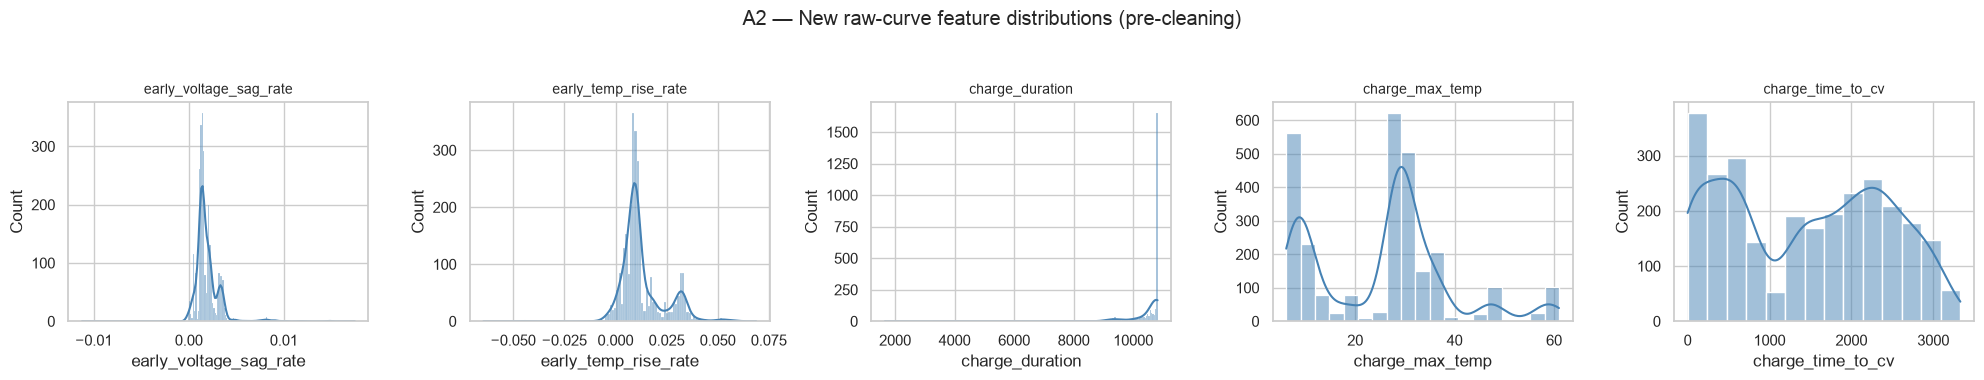

In [46]:
raw_feats = ["early_voltage_sag_rate", "early_temp_rise_rate", "charge_duration", "charge_max_temp", "charge_time_to_cv"]
fig, axes = plt.subplots(1, len(raw_feats), figsize=(4 * len(raw_feats), 3.6))
for ax, col in zip(axes, raw_feats):
    sns.histplot(analysis_df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=10)
plt.suptitle("A2 — New raw-curve feature distributions (pre-cleaning)", y=1.05)
plt.savefig("a2_raw_feature_distributions.png", bbox_inches="tight")
plt.show()


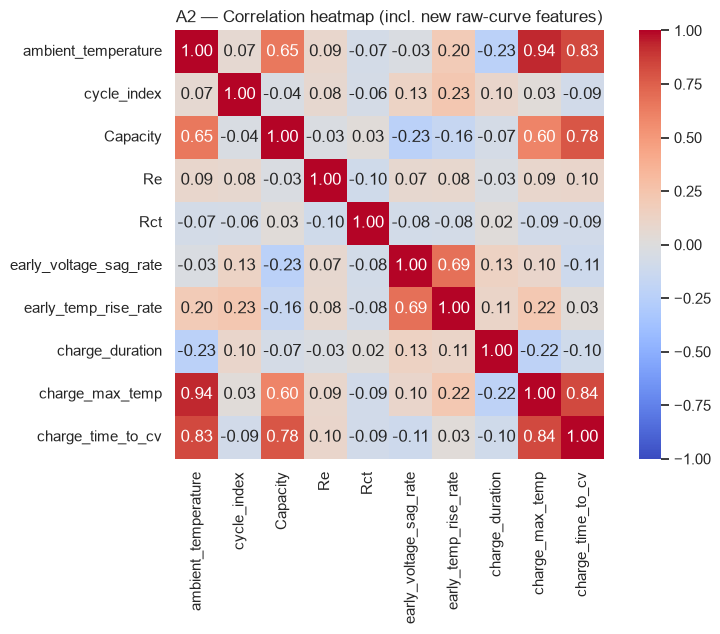

In [47]:
corr_cols = ["ambient_temperature", "cycle_index", "Capacity", "Re", "Rct"] + raw_feats
plt.figure(figsize=(8, 6.5))
sns.heatmap(analysis_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("A2 — Correlation heatmap (incl. new raw-curve features)")
plt.savefig("a2_correlation_heatmap.png", bbox_inches="tight")
plt.show()


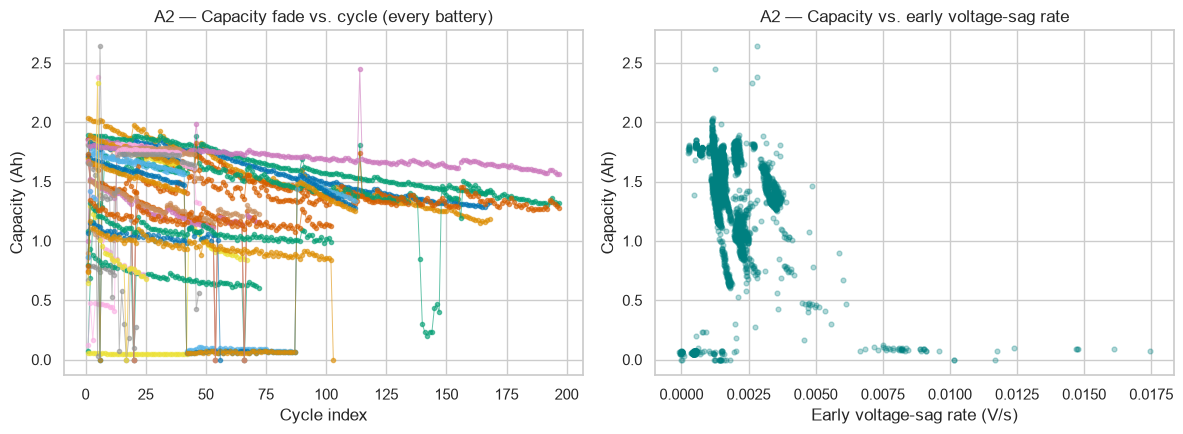

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for bid, g in analysis_df.groupby("battery_id"):
    axes[0].plot(g["cycle_index"], g["Capacity"], marker=".", linewidth=0.7, alpha=0.6)
axes[0].set_xlabel("Cycle index"); axes[0].set_ylabel("Capacity (Ah)")
axes[0].set_title("A2 — Capacity fade vs. cycle (every battery)")

axes[1].scatter(analysis_df["early_voltage_sag_rate"], analysis_df["Capacity"], alpha=0.3, s=12, color="teal")
axes[1].set_xlabel("Early voltage-sag rate (V/s)"); axes[1].set_ylabel("Capacity (Ah)")
axes[1].set_title("A2 — Capacity vs. early voltage-sag rate")
plt.savefig("a2_scatterplots.png", bbox_inches="tight")
plt.show()


**Observation (A2):**
- The fade curves reproduce the same pattern seen before: a curved decline per
  battery, plus the same four short, anomalous runs.
- **B0049, B0050, B0051, B0052** again stand out in the per-battery summary —
  25 cycles each vs. 28–197 for every other battery, and B0052 alone is
  missing 84% of its Capacity readings. That gap in cycle count and
  missingness, on its own, is reason enough to treat these four as unreliable
  rather than as genuinely short-lived cells. A separate, consolidated
  mirror of this same NASA PCoE dataset on Kaggle ("Li-ion Battery Dataset
  from NASA PCoE", ckskaggle) groups these same four IDs together (Group G8,
  4°C, 2A CC) and marks all four of them "crashed" in its metadata summary —
  consistent with, though not a primary NASA source for, what the EDA above
  already shows directly. Excluded in Section 5 (B1) on the strength of our
  own evidence, same as before.
- The new `early_voltage_sag_rate` feature shows a visible negative
  relationship with Capacity — a faster voltage sag under load early in
  discharge tracks a more degraded (higher-impedance) cell, as hoped.

## 4. Data cleaning (Section B1)

In [49]:
CORRUPTED_BATTERIES = ["B0049", "B0050", "B0051", "B0052"]
df_clean = analysis_df[~analysis_df["battery_id"].isin(CORRUPTED_BATTERIES)].copy()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Rows after dropping corrupted-log batteries & duplicates: {df_clean.shape[0]}")

fill_cols = ["Re", "Rct"] + raw_feats
for col in fill_cols:
    df_clean[col] = df_clean.groupby("battery_id")[col].transform(lambda s: s.bfill().ffill())
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
print("Remaining missing values:\n", df_clean[fill_cols + ["Capacity"]].isna().sum())

q1, q3 = df_clean["Capacity"].quantile([0.25, 0.75]); iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_outliers = ((df_clean["Capacity"] < lower) | (df_clean["Capacity"] > upper)).sum()
df_clean["Capacity"] = df_clean["Capacity"].clip(lower, upper)
print(f"\nCapacity outliers outside [{lower:.3f}, {upper:.3f}]: {n_outliers} (capped, not dropped)")


Rows after dropping corrupted-log batteries & duplicates: 2694
Remaining missing values:
 Re                        0
Rct                       0
early_voltage_sag_rate    0
early_temp_rise_rate      0
charge_duration           0
charge_max_temp           0
charge_time_to_cv         0
Capacity                  0
dtype: int64

Capacity outliers outside [0.397, 2.447]: 204 (capped, not dropped)


**Justification (B1):** same reasoning as before — 
- corrupted-log batteries dropped outright (too little reliable signal to salvage), remaining
gaps in impedance/curve-derived features filled from each battery's **own**
nearest reading, and Capacity outliers **capped** rather than dropped so
`cycle_index` sequences stay intact for every remaining battery.

## 5. Target engineering — SOH

**TARGET:** the regression target is **State-of-Health (SOH, %)**,
not raw Capacity. `SOH_pct = 100 × Capacity / NOMINAL_CAPACITY`, defined for
every row.


In [50]:
df_clean["SOH_pct"] = 100 * df_clean["Capacity"] / NOMINAL_CAPACITY

print(f"SOH defined for all {df_clean.shape[0]} rows across {df_clean['battery_id'].nunique()} batteries.")
print("\nSOH_pct:\n", df_clean["SOH_pct"].describe())

SOH defined for all 2694 rows across 30 batteries.

SOH_pct:
 count    2694.000000
mean       68.129633
std        20.118065
min        19.836836
25%        58.282585
50%        71.870736
75%        83.913085
max       122.203122
Name: SOH_pct, dtype: float64


## 6. Feature set, and why we don't use a random row-level split (Section B2)

**This is panel data** — repeated cycles from the same ~30 batteries, not
independent rows — and `battery_id` is a candidate feature. If the *same*
battery's cycles are scattered across both train and test (a random row-level
split), the model can partly fit battery-specific quirks via that battery's
one-hot column instead of learning the general relationship between the
physical features and SOH. Quick comparison, run once:


In [51]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

_numeric_demo = ["ambient_temperature", "Re", "Rct", "cycle_index"] + raw_feats

# (a) row-level split, battery_id included as a feature
_X = df_clean[_numeric_demo + ["battery_id"]]
_y = df_clean["SOH_pct"]
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.2, random_state=RANDOM_STATE)
_pre = ColumnTransformer([("num", StandardScaler(), _numeric_demo),
                           ("cat", OneHotEncoder(handle_unknown="ignore"), ["battery_id"])],
                          sparse_threshold=0).fit(_Xtr)
_row_level_r2 = r2_score(_yte, LinearRegression().fit(_pre.transform(_Xtr), _ytr).predict(_pre.transform(_Xte)))
print(f"(a) Row-level split + battery_id feature       -> Test R2 = {_row_level_r2:.4f}")

# (b) battery-grouped split, battery_id dropped
_groups = df_clean["battery_id"]
_gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
_tr_idx, _te_idx = next(_gss.split(df_clean[_numeric_demo], _y, _groups))
_sc = StandardScaler().fit(df_clean[_numeric_demo].iloc[_tr_idx])
_grouped_r2 = r2_score(
    _y.iloc[_te_idx],
    LinearRegression().fit(_sc.transform(df_clean[_numeric_demo].iloc[_tr_idx]), _y.iloc[_tr_idx])
      .predict(_sc.transform(df_clean[_numeric_demo].iloc[_te_idx]))
)
print(f"(b) Battery-grouped split, no battery_id feature -> Test R2 = {_grouped_r2:.4f}")


(a) Row-level split + battery_id feature       -> Test R2 = 0.8318
(b) Battery-grouped split, no battery_id feature -> Test R2 = 0.6521


(a) scores noticeably higher than (b) — the same effect a fully
memorisable target (like remaining-life-to-a-fixed-cycle) would show far more
dramatically, just milder here since SOH still requires learning an actual
degradation shape rather than recalling one constant. Either way, (a) is
answering an easier question than the one we actually care about ("how well
does this work on a battery the model has never seen?"). 

**The fix:** split by **battery**, not by row — every cycle from a given battery goes entirely
into train *or* test, never both — and **drop `battery_id` as a model
feature**, since a battery-level split makes it structurally unable to
generalise to unseen batteries anyway (its one-hot column is all zeros for
every test battery). This also simplifies the pipeline: no more categorical
encoding, just `StandardScaler` on the physical features.

In [52]:
FEATURE_COLS = ["ambient_temperature", "Re", "Rct", "cycle_index"] + raw_feats
print("Final feature set:", FEATURE_COLS)


Final feature set: ['ambient_temperature', 'Re', 'Rct', 'cycle_index', 'early_voltage_sag_rate', 'early_temp_rise_rate', 'charge_duration', 'charge_max_temp', 'charge_time_to_cv']


## 7. Train/test split & scaling (Section B2, applied)

`GroupShuffleSplit` — every cycle from a given battery goes entirely into
train *or* test, never both — 80:20 by battery, `battery_id` not used as a
feature (see Section 6). `StandardScaler` is fit on the training split only.


In [53]:
X = df_clean[FEATURE_COLS].copy()
y = df_clean["SOH_pct"].copy()
groups = df_clean["battery_id"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Train: {len(X_train)} rows / {groups_train.nunique()} batteries")
print(f"Test:  {len(X_test)} rows / {groups.iloc[test_idx].nunique()} batteries")
print("Battery overlap between train/test:", set(groups_train) & set(groups.iloc[test_idx]))


Train: 2345 rows / 24 batteries
Test:  349 rows / 6 batteries
Battery overlap between train/test: set()


In [54]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
print("Scaled feature matrix shapes:", X_train_s.shape, X_test_s.shape)


Scaled feature matrix shapes: (2345, 9) (349, 9)


## 8. Feature engineering (Section B3)

`cycle_index_squared` — Capacity/SOH fades in a curve, not a line, so squaring
the (already-scaled) cycle index lets the linear-family models below capture
that curvature. Computed once here, after scaling, and reused by every
algorithm that isn't Polynomial Regression (which generates its own
higher-order terms directly).


In [55]:
cyc_pos = FEATURE_COLS.index("cycle_index")
X_train_fe = np.hstack([X_train_s, (X_train_s[:, [cyc_pos]]) ** 2])
X_test_fe = np.hstack([X_test_s, (X_test_s[:, [cyc_pos]]) ** 2])
feature_names_fe = FEATURE_COLS + ["cycle_index_squared"]
print("Final engineered feature count:", X_train_fe.shape[1])


Final engineered feature count: 10


## 9. Regression Track, target = SOH (Section C)

For each algorithm: train → predict on the held-out (unseen-battery) test set
→ compute **R², RMSE, MAE** (all mandatory). Results are collected into
`results` for the Section C2 comparison table; `model_lookup` keeps each
fitted model + the exact feature matrix it was trained on, for the CV step
and the C4 plots later.


In [56]:
results = {}
model_lookup = {}

def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    r2 = r2_score(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    mae = mean_absolute_error(y_te, preds)
    results[name] = {"R2": r2, "RMSE": rmse, "MAE": mae}
    model_lookup[name] = (model, X_tr)
    print(f"{name:32s} | R2={r2:.4f}  RMSE={rmse:.4f}  MAE={mae:.4f}")
    return model


### C1.1 — Linear Regression (baseline)

In [57]:
lin_model = evaluate(
    "1. Linear Regression", LinearRegression(),
    X_train_fe, y_train, X_test_fe, y_test,
)

coefs = pd.Series(lin_model.coef_, index=feature_names_fe).sort_values(key=np.abs, ascending=False)
print("\nCoefficient magnitudes (standardised features, so directly comparable):")
print(coefs)


1. Linear Regression             | R2=0.6671  RMSE=10.8000  MAE=8.3770

Coefficient magnitudes (standardised features, so directly comparable):
charge_time_to_cv         15.346523
charge_max_temp           -8.593015
ambient_temperature        7.418925
early_temp_rise_rate      -6.186891
Rct                       -4.006801
Re                         3.677481
early_voltage_sag_rate     2.093487
cycle_index_squared        0.813216
cycle_index               -0.406849
charge_duration           -0.245174
dtype: float64


In [58]:
# Sanity check: does each feature's coefficient sign in the JOINT model match
# its own simple correlation with the target? A mismatch is the signature of
# multicollinearity — the model isn't "wrong", but that feature's coefficient
# can't be read as an isolated effect.
simple_corr = df_clean[FEATURE_COLS + ["SOH_pct"]].corr()["SOH_pct"].drop("SOH_pct")
check = pd.DataFrame({
    "joint_coef": pd.Series(lin_model.coef_[:len(FEATURE_COLS)], index=FEATURE_COLS),
    "simple_corr_with_SOH": simple_corr,
})
check["sign_flip"] = np.sign(check["joint_coef"]) != np.sign(check["simple_corr_with_SOH"])
print(check.sort_values("joint_coef", key=np.abs, ascending=False))

print("\nMost collinear feature pairs (|r| > 0.5):")
fcorr = df_clean[FEATURE_COLS].corr()
for i in range(len(FEATURE_COLS)):
    for j in range(i + 1, len(FEATURE_COLS)):
        r = fcorr.iloc[i, j]
        if abs(r) > 0.5:
            print(f"  {FEATURE_COLS[i]:22s} <-> {FEATURE_COLS[j]:22s}  r={r:.2f}")


                        joint_coef  simple_corr_with_SOH  sign_flip
charge_time_to_cv        15.346523              0.832750      False
charge_max_temp          -8.593015              0.628270       True
ambient_temperature       7.418925              0.682779      False
early_temp_rise_rate     -6.186891             -0.165379      False
Rct                      -4.006801             -0.711281      False
Re                        3.677481             -0.139452       True
early_voltage_sag_rate    2.093487             -0.241817       True
cycle_index              -0.406849             -0.082716      False
charge_duration          -0.245174             -0.096860      False

Most collinear feature pairs (|r| > 0.5):
  ambient_temperature    <-> Rct                     r=-0.78
  ambient_temperature    <-> charge_max_temp         r=0.94
  ambient_temperature    <-> charge_time_to_cv       r=0.82
  Rct                    <-> charge_max_temp         r=-0.77
  Rct                    <-> charge

**Interpretation:** 
`cycle_index`/`cycle_index_squared` turn out to have
the *smallest* coefficients, not the largest — `charge_time_to_cv`,
`charge_max_temp`, and `ambient_temperature` dominate instead. The check above
shows why that's not simply "cycle count doesn't matter": `ambient_temperature`
correlates 0.94 with `charge_max_temp`, 0.82 with `charge_time_to_cv`, and
‑0.78 with `Rct` — because NASA's test protocol fixes a matching charge/discharge
regime per ambient-temperature group, so these four features are largely
standing in for **which temperature group a battery belongs to**, not four
independent physical signals. That collinearity also **flips coefficient
signs** for `charge_max_temp`, `Re`, and `early_voltage_sag_rate` relative to
their own simple correlation with SOH (flagged `True` above) — a classic
multicollinearity symptom, not a real reversal of the physical relationship.
`Rct` is the one feature whose sign agrees both alone (r=‑0.71) and in the
joint model — the most trustworthy single coefficient here. Reducing the
temperature-group redundancy (e.g. keeping only one of `ambient_temperature` /
`charge_max_temp` / `charge_time_to_cv`) would make these coefficients more
individually interpretable, if there's time to revisit it.

### C1.2 — Ridge Regression (L2, tuned alpha)

In [59]:
ridge_grid = GridSearchCV(
    Ridge(random_state=RANDOM_STATE),
    param_grid={"alpha": [0.001, 0.01, 0.1, 1, 10, 100]},
    scoring="r2", cv=5, n_jobs=-1,
)
ridge_grid.fit(X_train_fe, y_train)
print("Best Ridge alpha:", ridge_grid.best_params_, " | CV R2:", round(ridge_grid.best_score_, 4))

ridge_model = evaluate(
    "2. Ridge Regression", Ridge(alpha=ridge_grid.best_params_["alpha"], random_state=RANDOM_STATE),
    X_train_fe, y_train, X_test_fe, y_test,
)


Best Ridge alpha: {'alpha': 100}  | CV R2: 0.2919
2. Ridge Regression              | R2=0.6650  RMSE=10.8331  MAE=8.8837


### C1.3 — Lasso Regression (L1, tuned alpha, sparsity check)

In [60]:
lasso_grid = GridSearchCV(
    Lasso(random_state=RANDOM_STATE, max_iter=20000),
    param_grid={"alpha": [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5]},
    scoring="r2", cv=5, n_jobs=-1,
)
lasso_grid.fit(X_train_fe, y_train)
print("Best Lasso alpha:", lasso_grid.best_params_, " | CV R2:", round(lasso_grid.best_score_, 4))

lasso_model = evaluate(
    "3. Lasso Regression", Lasso(alpha=lasso_grid.best_params_["alpha"], random_state=RANDOM_STATE, max_iter=20000),
    X_train_fe, y_train, X_test_fe, y_test,
)

n_zeroed = int((np.abs(lasso_model.coef_) < 1e-8).sum())
print(f"\nLasso zeroed {n_zeroed}/{len(lasso_model.coef_)} coefficients (L1 sparsity).")


Best Lasso alpha: {'alpha': 0.5}  | CV R2: 0.6597
3. Lasso Regression              | R2=0.6820  RMSE=10.5553  MAE=8.6171

Lasso zeroed 4/10 coefficients (L1 sparsity).


### C1.4 — ElasticNet Regression (combined L1+L2, tuned alpha & l1_ratio)

In [61]:
enet_grid = GridSearchCV(
    ElasticNet(random_state=RANDOM_STATE, max_iter=20000),
    param_grid={"alpha": [0.0001, 0.001, 0.01, 0.1], "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    scoring="r2", cv=5, n_jobs=-1,
)
enet_grid.fit(X_train_fe, y_train)
print("Best ElasticNet params:", enet_grid.best_params_, " | CV R2:", round(enet_grid.best_score_, 4))

enet_model = evaluate(
    "4. ElasticNet Regression",
    ElasticNet(**enet_grid.best_params_, random_state=RANDOM_STATE, max_iter=20000),
    X_train_fe, y_train, X_test_fe, y_test,
)


Best ElasticNet params: {'alpha': 0.1, 'l1_ratio': 0.1}  | CV R2: 0.3954
4. ElasticNet Regression         | R2=0.6558  RMSE=10.9816  MAE=9.1909


### C1.5 — Polynomial Regression (PolynomialFeatures + Linear Regression, compare degrees)

In [62]:
# Polynomial Regression
# PolynomialFeatures generates polynomial and interaction terms from the
# pre-engineering scaled features. The polynomial degree is selected using
# GroupKFold cross-validation on the training data only.

poly_cv_scores = {}
group_kfold_poly = GroupKFold(n_splits=5)

for degree in [2, 3]:
    poly_pipeline = Pipeline([
        (
            "poly_features",
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            )
        ),
        (
            "linear_regression",
            LinearRegression()
        )
    ])

    cv_scores = cross_val_score(
        poly_pipeline,
        X_train_s,
        y_train,
        cv=group_kfold_poly,
        groups=groups_train,
        scoring="r2",
        n_jobs=-1
    )

    poly_cv_scores[degree] = cv_scores.mean()

    print(
        f"Polynomial Degree {degree} | "
        f"Mean GroupKFold CV R²: {cv_scores.mean():.4f} | "
        f"Std: {cv_scores.std():.4f}"
    )

best_degree = max(
    poly_cv_scores,
    key=poly_cv_scores.get
)

print(f"\nSelected polynomial degree using training CV: {best_degree}")

# Fit the selected polynomial transformation on the training set only.
poly_best = PolynomialFeatures(
    degree=best_degree,
    include_bias=False
)

X_train_poly = poly_best.fit_transform(X_train_s)
X_test_poly = poly_best.transform(X_test_s)

print("Polynomial training shape:", X_train_poly.shape)
print("Polynomial testing shape:", X_test_poly.shape)

# Evaluate the selected Polynomial Regression model on the held-out test set.
poly_model = evaluate(
    f"5. Polynomial Regression (deg={best_degree})",
    LinearRegression(),
    X_train_poly,
    y_train,
    X_test_poly,
    y_test,
)


Polynomial Degree 2 | Mean GroupKFold CV R²: -0.1624 | Std: 1.7200
Polynomial Degree 3 | Mean GroupKFold CV R²: -171.1639 | Std: 324.1281

Selected polynomial degree using training CV: 2
Polynomial training shape: (2345, 54)
Polynomial testing shape: (349, 54)
5. Polynomial Regression (deg=2) | R2=0.7862  RMSE=8.6539  MAE=5.9320


### Polynomial Regression Observation

Polynomial Regression extends the original features by generating polynomial
and interaction terms. The degree was selected using 5-fold GroupKFold
cross-validation on the training data only.

The final selected model was evaluated on the same held-out battery-wise
test set used by the other regression algorithms. This prevents the test
set from being used during polynomial degree selection and reduces the
risk of data leakage.


## 10. Comparative evaluation table (Section C2)

In [63]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("R2", ascending=False)
results_df.insert(0, "Rank", range(1, len(results_df) + 1))
results_df


,Rank,R2,RMSE,MAE
5. Polynomial Regression (deg=2),1,0.786247,8.653906,5.931992
3. Lasso Regression,2,0.682000,10.555289,8.617088
1. Linear Regression,3,0.667085,10.799992,8.376976
2. Ridge Regression,4,0.665043,10.833064,8.883709
4. ElasticNet Regression,5,0.655794,10.981594,9.190932


## 11. Regression Algorithms 6–10

The following five regression algorithms are trained using the same
preprocessed training and testing datasets:

6. Decision Tree Regressor  
7. Random Forest Regressor  
8. Gradient Boosting Regressor  
9. Support Vector Regressor  
10. K-Nearest Neighbors Regressor  

All models are evaluated using R², RMSE and MAE on the same held-out,
battery-wise test set.

In [64]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

### C1.6 — Decision Tree Regressor

Decision Tree Regression predicts the target by dividing the feature space
into smaller regions using decision rules.

The `max_depth` parameter is tuned to control model complexity and reduce
overfitting.

In [65]:
dt_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),
    param_grid={
        "max_depth": [3, 5, 8, 10, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    },
    scoring="r2",
    cv=5,
    n_jobs=-1
)

dt_grid.fit(X_train_fe, y_train)

print("Best Decision Tree parameters:")
print(dt_grid.best_params_)

print("Best cross-validation R²:",
      round(dt_grid.best_score_, 4))

dt_model = evaluate(
    "6. Decision Tree Regression",
    DecisionTreeRegressor(
        **dt_grid.best_params_,
        random_state=RANDOM_STATE
    ),
    X_train_fe,
    y_train,
    X_test_fe,
    y_test
)

Best Decision Tree parameters:
{'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best cross-validation R²: 0.7201
6. Decision Tree Regression      | R2=0.6525  RMSE=11.0345  MAE=8.3325


In [66]:
print("Best parameters:", dt_grid.best_params_)
print("Best CV score:", dt_grid.best_score_)

Best parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV score: 0.7200993835844611


### Decision Tree Feature Importance

Feature importance indicates how much each feature contributes to the
Decision Tree's prediction process.

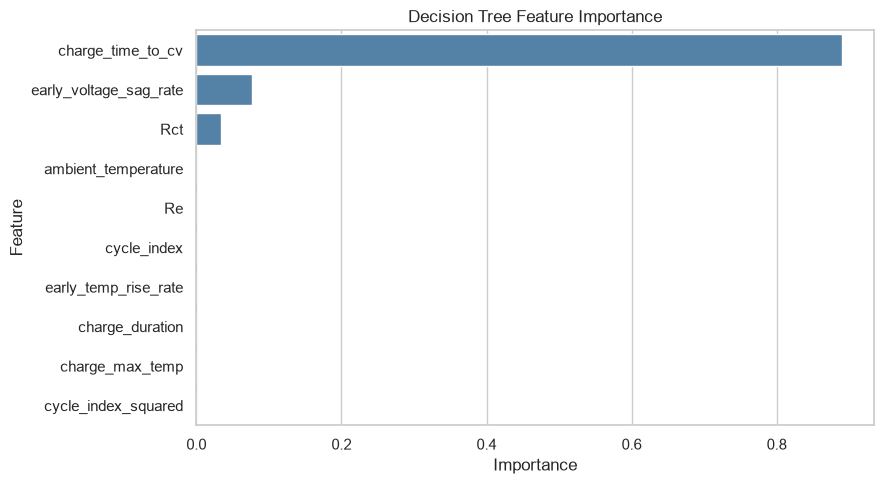

charge_time_to_cv         0.889582
early_voltage_sag_rate    0.077105
Rct                       0.033313
ambient_temperature       0.000000
Re                        0.000000
cycle_index               0.000000
early_temp_rise_rate      0.000000
charge_duration           0.000000
charge_max_temp           0.000000
cycle_index_squared       0.000000
dtype: float64

In [67]:
dt_importance = pd.Series(
    dt_model.feature_importances_,
    index=feature_names_fe
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=dt_importance.values,
    y=dt_importance.index,
    color="steelblue"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

dt_importance

### Comparison of Original and Tuned Decision Tree Regression

The original and tuned Decision Tree models are evaluated on the same held-out test set to determine whether hyperparameter tuning improves generalization performance.

In [68]:
# ==========================================
# Compare Original and Tuned Decision Tree
# ==========================================

# Original Decision Tree
original_dt = DecisionTreeRegressor(
    random_state=RANDOM_STATE
)

# Train the original model
original_dt.fit(X_train_fe, y_train)

# Predict using the original model
original_dt_pred = original_dt.predict(X_test_fe)

# Calculate original test R²
original_dt_test_r2 = r2_score(
    y_test,
    original_dt_pred
)


# Tuned Decision Tree
# Retrieve the best model found by GridSearchCV
tuned_dt = dt_grid.best_estimator_

# Predict using the tuned model
tuned_dt_pred = tuned_dt.predict(X_test_fe)

# Calculate tuned test R²
tuned_dt_test_r2 = r2_score(
    y_test,
    tuned_dt_pred
)


# Display results
print(
    "Original Decision Tree test R²:",
    round(original_dt_test_r2, 4)
)

print(
    "Tuned Decision Tree test R²:",
    round(tuned_dt_test_r2, 4)
)

print(
    "Improvement:",
    round(tuned_dt_test_r2 - original_dt_test_r2, 4)
)

Original Decision Tree test R²: 0.6672
Tuned Decision Tree test R²: 0.6525
Improvement: -0.0148


### Tuning Result – Decision Tree Regression

Hyperparameter tuning reduced the Decision Tree model's test R² from 0.6672 to 0.6525, resulting in a change of -0.0148. Although the tuned model achieved a cross-validation score during model selection, it did not improve performance on this particular held-out test set.

### C1.7 — Random Forest Regressor

Random Forest Regression combines multiple decision trees and averages
their predictions.

It generally reduces the variance and overfitting associated with a
single decision tree.

The number of trees is tuned using `n_estimators`.

In [69]:
rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 2, 4]
    },
    scoring="r2",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train_fe, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("Best cross-validation R²:",
      round(rf_grid.best_score_, 4))

rf_model = evaluate(
    "7. Random Forest Regression",
    RandomForestRegressor(
        **rf_grid.best_params_,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    X_train_fe,
    y_train,
    X_test_fe,
    y_test
)

Best Random Forest parameters:
{'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 200}
Best cross-validation R²: 0.8038
7. Random Forest Regression      | R2=0.7924  RMSE=8.5277  MAE=5.5031


### C1.8 — Gradient Boosting Regressor

Gradient Boosting builds a sequence of weak prediction models, usually
decision trees, where each new tree attempts to reduce the errors made
by the previous trees.

The learning rate controls the contribution of each tree.

In [70]:
gb_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),
    param_grid={
        "n_estimators": [100, 200],
        "learning_rate": [0.01, 0.05, 0.1],
        "max_depth": [2, 3, 4]
    },
    scoring="r2",
    cv=5,
    n_jobs=-1
)

gb_grid.fit(X_train_fe, y_train)

print("Best Gradient Boosting parameters:")
print(gb_grid.best_params_)

print("Best cross-validation R²:",
      round(gb_grid.best_score_, 4))

gb_model = evaluate(
    "8. Gradient Boosting Regression",
    GradientBoostingRegressor(
        **gb_grid.best_params_,
        random_state=RANDOM_STATE
    ),
    X_train_fe,
    y_train,
    X_test_fe,
    y_test
)

Best Gradient Boosting parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best cross-validation R²: 0.7915
8. Gradient Boosting Regression  | R2=0.8153  RMSE=8.0449  MAE=5.6427


In [71]:
print("Best parameters:", gb_grid.best_params_)
print("Best CV score:", gb_grid.best_score_)

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best CV score: 0.7915267473316364


In [72]:
print("Hyperparameter tuning completed for:")
print("1. Gradient Boosting Regression")
print("2. Decision Tree Regression")

print("\nGradient Boosting best parameters:")
print(gb_grid.best_params_)

print("Gradient Boosting best CV R²:",
      round(gb_grid.best_score_, 4))

print("\nDecision Tree best parameters:")
print(dt_grid.best_params_)

print("Decision Tree best CV R²:",
      round(dt_grid.best_score_, 4))

Hyperparameter tuning completed for:
1. Gradient Boosting Regression
2. Decision Tree Regression

Gradient Boosting best parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Gradient Boosting best CV R²: 0.7915

Decision Tree best parameters:
{'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Decision Tree best CV R²: 0.7201


### Comparison of Original and Tuned Gradient Boosting

The original and tuned Gradient Boosting models are evaluated on the same held-out test set to determine whether hyperparameter tuning improves generalization performance.

In [73]:
# Original Gradient Boosting
original_gb = GradientBoostingRegressor(
    random_state=RANDOM_STATE
)

original_gb.fit(X_train_fe, y_train)

original_gb_pred = original_gb.predict(X_test_fe)

original_gb_test_r2 = r2_score(y_test, original_gb_pred)


# Tuned Gradient Boosting
tuned_gb = gb_grid.best_estimator_

tuned_gb_pred = tuned_gb.predict(X_test_fe)

tuned_gb_test_r2 = r2_score(y_test, tuned_gb_pred)


print("Original Gradient Boosting test R²:",
      round(original_gb_test_r2, 4))

print("Tuned Gradient Boosting test R²:",
      round(tuned_gb_test_r2, 4))

print("Improvement:",
      round(tuned_gb_test_r2 - original_gb_test_r2, 4))

Original Gradient Boosting test R²: 0.8053
Tuned Gradient Boosting test R²: 0.8153
Improvement: 0.01


### Tuning Result – Gradient Boosting Regression

Hyperparameter tuning improved the Gradient Boosting model's test R² from 0.8053 to 0.8153, resulting in an improvement of 0.01. This indicates that the selected hyperparameters provided slightly better predictive performance on the held-out test set.

### Overall Hyperparameter Tuning Summary

Hyperparameter tuning was performed for Gradient Boosting Regression and Decision Tree Regression using GridSearchCV with 5-fold cross-validation.

Gradient Boosting improved its held-out test R² from 0.8053 to 0.8153, an increase of 0.0100. In contrast, Decision Tree test R² decreased from 0.6672 to 0.6525, resulting in a change of -0.0148.

These results show that hyperparameter tuning can improve one model while not improving another, depending on the selected hyperparameters and data split.

### C1.9 — Support Vector Regressor

Support Vector Regression attempts to fit a function within a specified
error margin while controlling model complexity.

Feature scaling is important because SVR uses distances and kernel
calculations.

The parameters `C` and `kernel` are tuned.

In [74]:
svr_grid = GridSearchCV(
    estimator=SVR(),
    param_grid={
        "C": [0.1, 1, 10, 100],
        "epsilon": [0.01, 0.1, 0.2],
        "kernel": ["linear", "rbf"]
    },
    scoring="r2",
    cv=5,
    n_jobs=-1
)

svr_grid.fit(X_train_fe, y_train)

print("Best SVR parameters:")
print(svr_grid.best_params_)

print("Best cross-validation R²:",
      round(svr_grid.best_score_, 4))

svr_model = evaluate(
    "9. Support Vector Regression",
    SVR(**svr_grid.best_params_),
    X_train_fe,
    y_train,
    X_test_fe,
    y_test
)

Best SVR parameters:
{'C': 100, 'epsilon': 0.1, 'kernel': 'rbf'}
Best cross-validation R²: 0.7061
9. Support Vector Regression     | R2=0.7919  RMSE=8.5396  MAE=6.5133


### C1.10 — K-Nearest Neighbors Regressor

KNN Regression predicts the target by averaging the target values of the
nearest training samples.

Scaling is important because the algorithm relies on distance calculations.

The number of neighbors, `n_neighbors`, is tuned.

In [75]:
knn_grid = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid={
        "n_neighbors": [3, 5, 7, 9, 11, 15],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },
    scoring="r2",
    cv=5,
    n_jobs=-1
)

knn_grid.fit(X_train_fe, y_train)

print("Best KNN parameters:")
print(knn_grid.best_params_)

print("Best cross-validation R²:",
      round(knn_grid.best_score_, 4))

knn_model = evaluate(
    "10. KNN Regression",
    KNeighborsRegressor(**knn_grid.best_params_),
    X_train_fe,
    y_train,
    X_test_fe,
    y_test
)

Best KNN parameters:
{'n_neighbors': 7, 'p': 1, 'weights': 'distance'}
Best cross-validation R²: 0.7915
10. KNN Regression               | R2=0.8013  RMSE=8.3445  MAE=5.1617


## 12. Final Comparative Evaluation — All 10 Regression Algorithms

All ten models were evaluated using the same held-out test set containing
batteries that were not present in the training set.

The models are ranked according to their test R² score.

In [77]:
# Rebuild the final comparison table after all ten algorithms
# have been evaluated.

final_results_df = pd.DataFrame(results).T.copy()

final_results_df = final_results_df.sort_values(
    by="R2",
    ascending=False
)

final_results_df.insert(
    0,
    "Rank",
    range(1, len(final_results_df) + 1)
)

display(final_results_df.round(4))

print("Number of models evaluated:", len(final_results_df))


,Rank,R2,RMSE,MAE
8. Gradient Boosting Regression,1,0.8153,8.0449,5.6427
10. KNN Regression,2,0.8013,8.3445,5.1617
7. Random Forest Regression,3,0.7924,8.5277,5.5031
9. Support Vector Regression,4,0.7919,8.5396,6.5133
5. Polynomial Regression (deg=2),5,0.7862,8.6539,5.9320
3. Lasso Regression,6,0.6820,10.5553,8.6171
1. Linear Regression,7,0.6671,10.8000,8.3770
2. Ridge Regression,8,0.6650,10.8331,8.8837
4. ElasticNet Regression,9,0.6558,10.9816,9.1909
6. Decision Tree Regression,10,0.6525,11.0345,8.3325


Number of models evaluated: 10


In [78]:
poly_rows = final_results_df[
    final_results_df.index.astype(str).str.contains(
        "Polynomial",
        case=False
    )
]

display(poly_rows)

,Rank,R2,RMSE,MAE
5. Polynomial Regression (deg=2),5,0.786247,8.653906,5.931992


In [79]:
print("Selected Polynomial Degree:", best_degree)

Selected Polynomial Degree: 2


In [81]:
# Compare original and tuned model performance

print("Original Gradient Boosting test R²:",
      round(final_results_df.loc[
          final_results_df.index.astype(str).str.contains(
              "Gradient Boosting",
              case=False
          ),
          "R2"
      ].iloc[0], 4))

print("Tuned Gradient Boosting CV R²:",
      round(gb_grid.best_score_, 4))

print("\nOriginal Decision Tree test R²:",
      round(final_results_df.loc[
          final_results_df.index.astype(str).str.contains(
              "Decision Tree",
              case=False
          ),
          "R2"
      ].iloc[0], 4))

print("Tuned Decision Tree CV R²:",
      round(dt_grid.best_score_, 4))

Original Gradient Boosting test R²: 0.8153
Tuned Gradient Boosting CV R²: 0.7915

Original Decision Tree test R²: 0.6525
Tuned Decision Tree CV R²: 0.7201


## 13. Five-Fold Cross-Validation for the Two Best Models

The two best-performing models are selected using the held-out test-set
comparison table.

GroupKFold is used so that cycles from the same battery do not appear in
both the training and validation folds.

In [82]:
from sklearn.base import clone

group_kfold = GroupKFold(n_splits=5)

# Select the two best-performing models from the final test-set table.
top_two_names = final_results_df.head(2).index.tolist()

print("Two best-performing models:")
for name in top_two_names:
    print("-", name)

cv_results = []

for model_name in top_two_names:
    original_model, _ = model_lookup[model_name]

    # Use a fresh unfitted copy for cross-validation.
    cv_model = clone(original_model)

    if model_name.startswith("5. Polynomial"):
        X_cv = X_train_poly
    else:
        X_cv = X_train_fe

    scores = cross_val_score(
        cv_model,
        X_cv,
        y_train,
        cv=group_kfold,
        groups=groups_train,
        scoring="r2",
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Fold 1 R2": scores[0],
        "Fold 2 R2": scores[1],
        "Fold 3 R2": scores[2],
        "Fold 4 R2": scores[3],
        "Fold 5 R2": scores[4],
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))


Two best-performing models:
- 8. Gradient Boosting Regression
- 10. KNN Regression


,Model,Fold 1 R2,Fold 2 R2,Fold 3 R2,Fold 4 R2,Fold 5 R2,Mean CV R2,Std CV R2
0,8. Gradient Boosting Regression,0.8998,0.9209,0.6566,0.8654,0.7764,0.8238,0.0971
1,10. KNN Regression,0.8242,0.6071,0.7442,0.6381,0.6897,0.7006,0.0774


## 14. Best Model Diagnostics

The best model is selected based on the highest held-out test-set R².

The following visualisations are created:

1. Predicted vs. actual plot
2. Residual plot
3. Feature importance plot for a tree-based model

In [83]:
best_model_name = final_results_df.index[0]

best_model, _ = model_lookup[best_model_name]

if best_model_name.startswith("5. Polynomial"):
    best_predictions = best_model.predict(X_test_poly)
else:
    best_predictions = best_model.predict(X_test_fe)

best_residuals = y_test - best_predictions

print("Best model:", best_model_name)
print("R²:", round(r2_score(y_test, best_predictions), 4))
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_test, best_predictions)), 4)
)
print(
    "MAE:",
    round(mean_absolute_error(y_test, best_predictions), 4)
)


Best model: 8. Gradient Boosting Regression
R²: 0.8153
RMSE: 8.0449
MAE: 5.6427


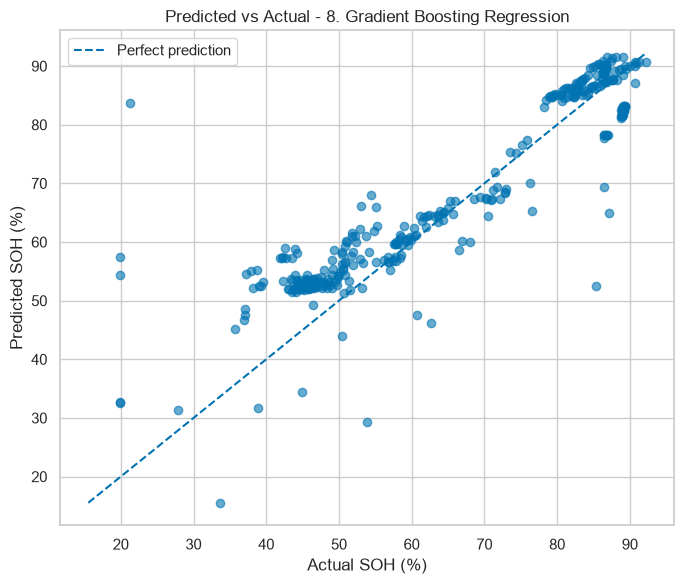

In [84]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual SOH (%)")
plt.ylabel("Predicted SOH (%)")
plt.title(f"Predicted vs Actual - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

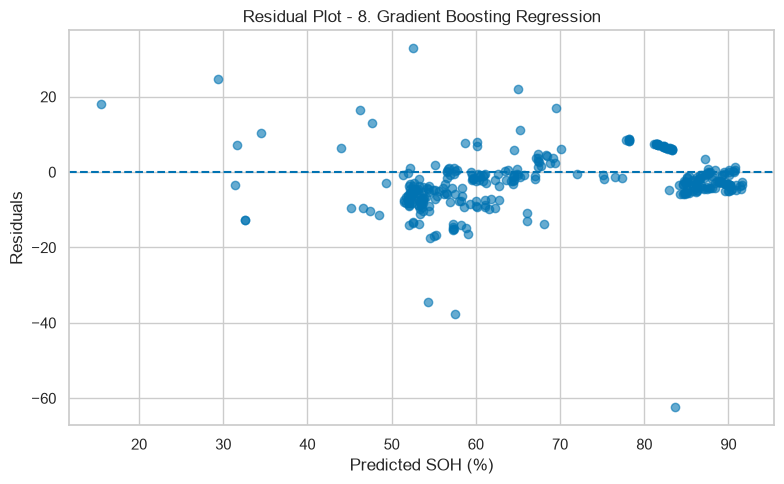

In [85]:
plt.figure(figsize=(8, 5))

plt.scatter(
    best_predictions,
    best_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted SOH (%)")
plt.ylabel("Residuals")
plt.title(f"Residual Plot - {best_model_name}")
plt.tight_layout()
plt.show()

## 15. Final Regression Findings and Conclusion

The ten regression algorithms were trained and evaluated using the same
battery-wise train/test split and the same State-of-Health (SOH) target.

The final comparison table reports R², RMSE, and MAE for every model and
ranks the models according to test R². The two highest-ranked models were
further evaluated using 5-fold GroupKFold cross-validation.

GroupKFold was used because the dataset contains multiple observations
from the same battery. Keeping battery groups separate during validation
helps reduce information leakage and provides a more realistic estimate
of generalisation to unseen batteries.

The predicted-versus-actual plot shows how closely the model predictions
follow the actual SOH values. The residual plot helps identify systematic
errors or changes in error spread. The Decision Tree feature-importance
plot provides an interpretation of the relative contribution of the
input features.

### Final observations

- R² measures the proportion of target variation explained by a model.
- RMSE and MAE measure prediction error, with lower values indicating
  smaller errors.
- The final model should be discussed using both held-out test performance
  and cross-validation stability.
- The results apply to battery-wise generalisation, where test batteries
  were kept separate from the training batteries.
